# Credit Risk Scorecard — 01: Exploratory Data Analysis

Goal: To predict which borrowers become seriously delinquent within 2 years, using the Kaggle Give Me Some Credit dataset (150K borrowers). This is an application scorecard, meaning the borrower is scored at the point of decision using only information a lender would have at application time. In this notebook I explore the raw data to find quality issues and identify which features predict default. All treatment decisions are summarized in the decision table at the end.

## Data Dictionary

**SeriousDlqin2yrs:** Person experienced 90 days past due delinquency or worse (target variable)

**RevolvingUtilizationOfUnsecuredLines:** Total balance on credit cards and personal lines of credit (excluding real estate and installment debt like car loans) divided by the sum of credit limits

**age:** Age of borrower in years

**NumberOfTime30-59DaysPastDueNotWorse:** Number of times borrower has been 30–59 days past due but no worse in the last 2 years

**DebtRatio:** Monthly debt payments, alimony, and living costs divided by monthly gross income

**MonthlyIncome:** Monthly income

**NumberOfOpenCreditLinesAndLoans:** Number of open loans (installment, like a car loan or mortgage) and lines of credit (e.g. credit cards)

**NumberOfTimes90DaysLate:** Number of times borrower has been 90 days or more past due

**NumberRealEstateLoansOrLines:** Number of mortgage and real estate loans, including home equity lines of credit

**NumberOfTime60-89DaysPastDueNotWorse:** Number of times borrower has been 60–89 days past due but no worse in the last 2 years

**NumberOfDependents:** Number of dependents in family, excluding themselves (spouse, children, etc.)

In [4]:
import pandas as pd
df = pd.read_csv('../data/cs-training.csv', index_col=0)
df.shape, df.dtypes

((150000, 11),
 SeriousDlqin2yrs                          int64
 RevolvingUtilizationOfUnsecuredLines    float64
 age                                       int64
 NumberOfTime30-59DaysPastDueNotWorse      int64
 DebtRatio                               float64
 MonthlyIncome                           float64
 NumberOfOpenCreditLinesAndLoans           int64
 NumberOfTimes90DaysLate                   int64
 NumberRealEstateLoansOrLines              int64
 NumberOfTime60-89DaysPastDueNotWorse      int64
 NumberOfDependents                      float64
 dtype: object)

In [5]:
df.head()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


150,000 rows × 11 columns: one target (SeriousDlqin2yrs) and 10 features covering credit utilization, age, payment history, income and debt. A lender would have this information at application time.

In [7]:
df['SeriousDlqin2yrs'].mean()

0.06684

Only 6.7% of borrowers default, so there is roughly a 14:1 class imbalance. This means accuracy would be misleading, because a model that always guessed "no default" would score 93.3%. So I'll evaluate with AUC and KS instead, and stratify the train/test split so the test set keeps the same 6.7% default rate.

I am also not going to resample the data. A scorecard has to output a calibrated probability of default, not just a ranking, and resampling with something like SMOTE breaks that calibration. With about 10,000 defaults in the data there are plenty of events for logistic regression to work with. If the imbalance does need handling later, class_weight is the simpler and reversible option.

In [9]:
df.isna().sum()

SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

In [10]:
missing = df.isna().sum()
(missing[missing > 0] / len(df)).round(4)

MonthlyIncome         0.1982
NumberOfDependents    0.0262
dtype: float64

The `MonthlyIncome` is missing for 29,731 borrowers which is around 20% which is too many to drop. Before imputing, I'll test whether missingness itself correlates with default. `NumberOfDependents` has 2.6% missing.

In [12]:
(df['MonthlyIncome'].isna() & df['NumberOfDependents'].isna()).sum(), df['NumberOfDependents'].isna().sum()

(3924, 3924)

All 3,924 rows missing `NumberOfDependents` are also missing `MonthlyIncome` which means the dependents gaps are a subset of the income gaps. So this is one missingness mechanism. These records are likely missing a whole block of application data. Treatment-wise, both columns will be handled by the same "income unknown" logic later rather than doing two separate imputation strategies.

In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,98.0


From this describe function I need to further investigate anomalies:
- **`RevolvingUtilizationOfUnsecuredLines`**: median is 0.15 but max is 50,708. Utilization
  is credit used ÷ credit limit, so values slightly above 1 are plausible but 50,708 is not.
- **`age`**: min is 0, an impossible value for a credit applicant.
- **The three past-due counts** (`30-59`, `60-89`, `90+`): all have max 98 with 75th
  percentile 0. No plausible payment history contains 98 late episodes these look like codes standing in for a status, not real counts.
- **`DebtRatio`**: median 0.37 (sensible — debt payments ÷ income) but max 329,664.
  A ratio in the hundreds of thousands means the denominator is broken for some rows.
- **`MonthlyIncome`**: max is `$`3,008,750 and median is `$`5400 hence heavy right tail. Min is `$`0:
  a recorded value, so maybe a distinct group from the 29,731 missing.

The quantiles do the distribution work here: every financial variable is severely
right-skewed (mean ≫ median throughout), which is expected for monetary data and does not need to be transformed because WOE(Weight of Evidence) binning means that the model will see the bin membership as opposed to just the raw magnitude..

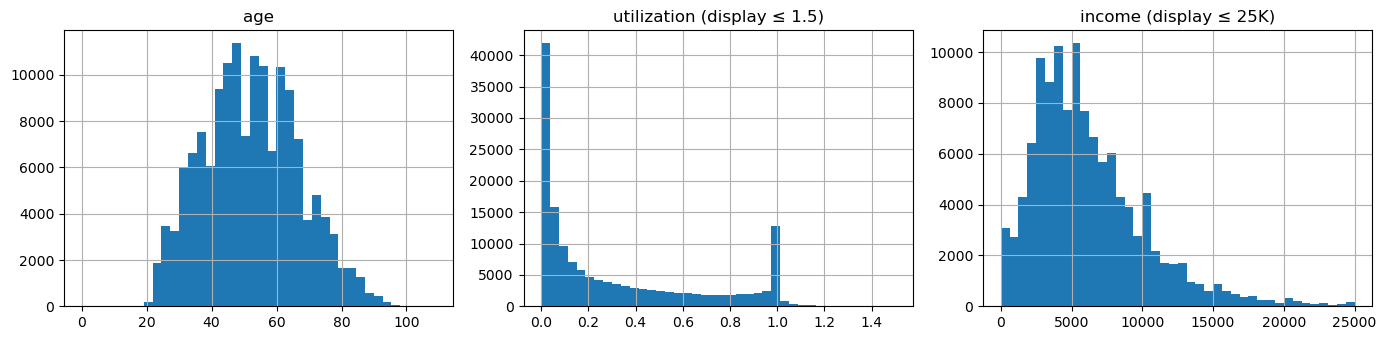

In [16]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
df['age'].hist(bins=40, ax=axes[0]); axes[0].set_title('age')
df.loc[df['RevolvingUtilizationOfUnsecuredLines'] <= 1.5,
       'RevolvingUtilizationOfUnsecuredLines'].hist(bins=40, ax=axes[1])
axes[1].set_title('utilization (display ≤ 1.5)')
df.loc[df['MonthlyIncome'] <= 25000, 'MonthlyIncome'].hist(bins=40, ax=axes[2])
axes[2].set_title('income (display ≤ 25K)')
plt.tight_layout()

**Age:** roughly symmetric, with most borrowers between 30 and 75 and the peak near 50. The single age = 0 row is too small to see here.

**Utilization:** most borrowers are close to 0, and there is a second spike right at 1, which is borrowers who have maxed out their credit.

**Income:** even with values above 25K cut off for display, income is right-skewed, with most borrowers between about 2K and 10K a month.

In [18]:
(df['RevolvingUtilizationOfUnsecuredLines'] > 1).sum()

3321

3,321 borrowers (2.2%) have utilization above 1. However the count alone can't tell us
whether these are data errors or genuinely over-limit borrowers. I need to separate the utilization into bands and see the number in each band and check the average default rate of each band

In [20]:
util = df['RevolvingUtilizationOfUnsecuredLines'] 
bands = pd.cut(util, [-0.001, 0.1, 0.5, 1, 10, util.max()])
df.groupby(bands, observed=True)['SeriousDlqin2yrs'].agg(['mean', 'count'])

,mean,count
RevolvingUtilizationOfUnsecuredLines,,
"(-0.001, 0.1]",0.018104,64404
"(0.1, 0.5]",0.041099,44308
"(0.5, 1.0]",0.152817,37967
"(1.0, 10.0]",0.396104,3080
"(10.0, 50708.0]",0.070539,241


Across the normal range, default risk climbs steeply and monotonically with
utilization (1.8% to 4.1% and then to 15.3%). Thus in this data, honestly-reported utilization is
a strong risk signal. The (1, 10] band continues the same climb as 3,080 borrowers
defaulting at 39.6%, which is six times the base rate and the riskiest group in the dataset. This is how usually over-limit borrowers behave, so these values are real and seem normal.

The (10, 50708] band tells a completely different story. These 241 rows claim the worst credit usage in the dataset, yet they default at 7.1%, which is right at the 6.7% baseline. Extreme values attached to average behaviour means the field is not measuring utilization for these rows, so they are data errors.

**As a final decision I have decided to cap utilization at 10**. Capping at 1
would fold the 3,080 highest-risk borrowers (39.6% default) into the (0.5, 1] band
(15.3% default), destroying the strongest risk signal in the feature to satisfy a
common general assumption the data is showing to violate. **Revised in notebook 02:**: values above 10 are set to missing (their own bin) instead of capped, because capping would place 241 known-error rows into the riskiest band and dilute its default rate from 39.6% to about 37%.

In [22]:
(df['age'] < 18).sum()

1

In [23]:
df.loc[df['age']<18]

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
65696,0,1.0,0,1,0.436927,6000.0,6,0,2,0,2.0


Only 1 row has an age below 18 which is the age = 0 row. Inspecting the full row showsthat most of the other values are normal so there wasn't an error receiving information.
**My decision is to drop this row**. The alternative is to let it fall in the missing bin and then to treat it. The reasoning I am dropping is because one row in 150,000 cannot shift any estimate and cannot represent a subpopulation.

In [25]:
df['NumberOfTimes90DaysLate'].value_counts().sort_index()

NumberOfTimes90DaysLate
0     141662
1       5243
2       1555
3        667
4        291
5        131
6         80
7         38
8         21
9         19
10         8
11         5
12         2
13         4
14         2
15         2
17         1
96         5
98       264
Name: count, dtype: int64

The distribution decays smoothly from 141,662 borrowers with zero 90-day
delinquencies down to 1 borrower at 17 and then stops. There is nothing between
17 and 96, and then 5 rows at 96 and 264 at exactly 98. Two features of that shape
show that there is something wrong. First problem is the gap. A real count variable does not skip 78
consecutive values and then resume. Second issue is that there is a pile up of 264 rows sit on the single
value 98, more than the combined count of every value from 6 through 17 (182). Real
delinquency counts usually thin out as they grow.They do not spike at one specific large
number.

These are sentinel values: codes standing in for a status rather than a literal
count. 98 would imply roughly 24 years of continuous 90-day delinquency episodes.
Two things this cell cannot tell us will determine the treatment: whether the same 
rows carry sentinel values in the other two past-due columns, and how those borrowers 
actually default.

In [27]:
sent = df[df['NumberOfTimes90DaysLate'] >= 96]
len(sent), (sent['NumberOfTime30-59DaysPastDueNotWorse'] >= 96).sum(), (sent['NumberOfTime60-89DaysPastDueNotWorse'] >= 96).sum()

(269, 269, 269)

All 269 rows carrying a sentinel in `NumberOfTimes90DaysLate` carry one in
`NumberOfTime30-59DaysPastDueNotWorse` and `NumberOfTime60-89DaysPastDueNotWorse`
as well.

If they were real counts, each column would be counting something different for each borrower, so it wouldn't make sense for the same 269 people to all have 96 or 98 in every column. The three columns must have been filled in together by the same process, otherwise there is no way that all these three columns would overlap like this. The next question is whether these flagged borrowers default more than normal.

In [29]:
sent['SeriousDlqin2yrs'].mean()

0.5464684014869888

The 269 borrowers with sentinel values default at 54.6%, which is about 8 times the 6.7% baseline. So whatever status these codes stand for, it is a very strong sign of risk, and these are the riskiest borrowers in the dataset.

**Decision: keep these rows and give the sentinel its own WOE bin in each of the three past-due columns.** The alternatives are all worse. Dropping them would throw away the strongest risk signal in the data. Treating 96 and 98 as real counts would let a value 400 times larger than the biggest genuine count (17) dominate the model. Imputing them with a median or a zero would turn the worst borrowers in the dataset into ordinary ones. Binning avoids all three, because the bin carries whatever default rate it actually has and I do not need to assume anything about what the code means.

In [31]:

df.groupby(df['MonthlyIncome'].isna())['SeriousDlqin2yrs'].mean()

MonthlyIncome
False    0.069486
True     0.056137
Name: SeriousDlqin2yrs, dtype: float64

Borrowers with missing income default at **5.6%**, against **6.9%** for those with
income reported — a 1.3 point gap, and in the opposite direction to what I expected
(I assumed unreported income would signal a riskier applicant). Missingness is
therefore informative: the fact that income is absent carries its own signal about
default, independent of what the income value would have been.

The direction suggests these are not evasive applicants but records where an income
field was never populated — consistent with the finding above that all 3,924 rows
missing `NumberOfDependents` are inside this same group, i.e. a whole block of
application data is absent rather than one field being withheld.

**Decision: give missing income its own WOE bin rather than imputing it.** Median
imputation — the common treatment — would place 29,731 borrowers in the middle of
the income distribution and erase a measurable 1.3 point difference in default rate.
If a numeric imputation is ever required for a challenger model, it must be paired
with a missing-indicator flag so the signal survives.

In [33]:
df.loc[df['MonthlyIncome'].notna(), 'DebtRatio'].median(), df.loc[df['MonthlyIncome'].isna(), 'DebtRatio'].median()

(0.296022604, 1159.0)

In [34]:
big = df['DebtRatio'] > 5
big.sum(), ((big) & (df['MonthlyIncome'].isna() | (df['MonthlyIncome'] == 0))).sum() / big.sum()

(29646, 0.9709235647304864)

In [35]:
broken_income = df['MonthlyIncome'].isna() | (df['MonthlyIncome'] == 0)
broken_income.sum(), (big & broken_income).sum() / broken_income.sum()

(31365, 0.9177108241670652)

### DebtRatio

The describe() output flagged a maximum of 329,664 on a variable defined as monthly debt payments
÷ monthly income. A ratio that large is not going to come from a very large numerator as no borrower
services their debt at three hundred thousand times their income value. Thus the denominator must
be broken(very low) for those rows. That predicts something that we can test which is that the implausible ratios
should cluster in rows where income is unavailable.

Splitting the median by income availability confirms it immediately. Where income is
present, median DebtRatio is **0.30** which is a sensible debt-service ratio, and exactly the
kind of figure a lender would underwrite against. Where income is missing, the median
is **1,159**, which is meaningless as a ratio but entirely plausible as a dollar
amount of monthly debt payments. The field appears to hold the raw numerator wherever
income was unavailable, rather than being left blank.

Quantifying the overlap: **29,646 rows** have DebtRatio > 5 (debt payments exceeding
five times income), which is 19.8% of the dataset. The same share as missing income,
computed independently. Of those rows, **97.1%** have income that is missing or zero.
The failure runs in both directions as roughly 92% of rows with broken income also carry a
broken DebtRatio. Two fields sharing one denominator fail together.

**Decision: DebtRatio only means something where income is present and above zero.**
For the other 31K rows the stored number is not a ratio at all, it looks like a
dollar amount of debt payments, so it is a different measurement in different units
sitting in the same column. Those rows belong in the same "income unknown" group as
the income field.

Capping these values at the 99th percentile would be the common fix, but I think it would be the
wrong one. It would turn 1,159 into something that looks like a believable ratio and
hide the fact that the field failed at all.

In [37]:
(df['MonthlyIncome'] == 0).sum(), df.loc[df['MonthlyIncome'] == 0, 'SeriousDlqin2yrs'].mean()

(1634, 0.04039167686658507)

1,634 borrowers have income recorded as exactly 0 dollars, and they default at 4.0%. That is lower than both the missing-income group (5.6%) and the overall base rate (6.7%), so 0 dollar income is a third group and not just another form of missing. A likely explanation is retirees or people living on household income and savings rather than wages, who have credit but report no earnings.

**Decision: keep 0 dollar separate from missing income when binning.** These rows also sit inside the DebtRatio problem from the previous section, since dividing by zero income breaks the ratio the same way a missing value does.

In [39]:
df.groupby(pd.cut(df['age'], [18, 30, 40, 50, 60, 70, 110]), observed=True)['SeriousDlqin2yrs'].agg(['mean', 'count'])

,mean,count
age,,
"(18, 30]",0.115646,10757
"(30, 40]",0.098196,24339
"(40, 50]",0.082570,35037
"(50, 60]",0.061742,34806
"(60, 70]",0.034714,27424
"(70, 110]",0.022567,17636


Default risk falls steadily with age, from 11.6% for borrowers aged 18-30 down to
2.3% for those over 70. The decline holds at every step and every band has a large
sample, so this is a  monotonic relationship and it matches what you would
expect: older borrowers have more settled income, more assets, and longer credit
histories.

Because the relationship is monotonic, **age can take a monotonic binning constraint**,
which keeps the scorecard interpretable without losing fit.

In [41]:
df.groupby(df['NumberRealEstateLoansOrLines'].clip(upper=5))['SeriousDlqin2yrs'].agg(['mean', 'count'])

,mean,count
NumberRealEstateLoansOrLines,,
0,0.083149,56188
1,0.052505,52338
2,0.055993,31522
3,0.066984,6300
4,0.089401,2170
5,0.151822,1482


Values are clipped at 5 for display, so the last row means 5 or more (the
maximum is 54).

This feature is not monotonic. Risk is highest for borrowers with no real estate
lines (8.3%), drops to its lowest at one (5.3%). Then it climbs steadily with 5.6% at two,
6.7% at three, 8.9% at four, and 15.2% at five or more.
Borrowers with no property have no secured credit and a thinner file. One mortgage
signals a stable homeowner who qualified for a secured loan. Beyond two, borrowers
are increasingly leveraged in property, and the risk rises with it. Hence the trend makes sense with the data.

**Decision: do not force monotonic bins on this feature.** A monotonic constraint would
flatten the U-shape and lose signal at both ends. Bins should respect the shape,
roughly 0 / 1-2 / 3-4 / 5+.

`NumberOfOpenCreditLinesAndLoans` and `NumberOfDependents` are not examined individually
here. Both will be covered by the IV ranking later, which computes
association for every feature

In [43]:
clean = df[df['NumberOfTimes90DaysLate'] < 96]
cols = ['NumberOfTime30-59DaysPastDueNotWorse', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfTimes90DaysLate']
clean[cols].corr()

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate
NumberOfTime30-59DaysPastDueNotWorse,1.000000,0.305876,0.218147
NumberOfTime60-89DaysPastDueNotWorse,0.305876,1.000000,0.294638
NumberOfTimes90DaysLate,0.218147,0.294638,1.000000


Sentinel rows are excluded before computing this. The 269 flagged records carry
identical extreme values in all three columns, so leaving them in would manufacture
correlation that reflects one upstream process rather than borrower behaviour.

Correlations among the three past-due counters are modest: 0.31 between the 30-59
and 60-89 day tiers, 0.29 between 60-89 and 90+, and 0.22 between 30-59 and 90+.
Adjacent tiers correlate more strongly than distant ones, consistent with these
tracking an escalating progression rather than measuring the same thing three times.

**Decision: keep all three features.** They capture distinct severity tiers and are not
redundant enough to threaten coefficient stability in a logistic regression in notebook 03.

## Decision table
Every issue found in this notebook, what the data showed, and how it will be handled.

| Issue | Finding | Decision |
|---|---|---|
| Class imbalance | 6.7% default rate, roughly 14:1 | Stratified split, evaluate with AUC and KS, no resampling |
| Utilization > 1 |Real signal up to 10 (39.6% default); values above 10 default at baseline (7.1%), so they are errors | Values above 10 set to missing (own bin), not capped; threshold at 10, not 1. Revised in notebook 02 |
| 96/98 sentinels | 269 rows, present in all three past-due columns, default at 54.6% | Keep rows, own WOE bin in each column |
| DebtRatio blow-ups | 29,646 rows above 5, and 97.1% of them have missing or \$0 income | Only interpretable where income is present and positive, rest go to the income unknown group |
| Missing income | 19.8% missing, default 5.6% vs 6.9%, so informative | Own WOE bin, no median imputation |
| \$0 income | 1,634 rows, default at 4.0%, below both missing and baseline | Keep separate from missing when binning |
| Missing dependents | 3,924 rows, all inside the missing income group | Same treatment as missing income |
| age = 0 | 1 row, rest of the record is normal | Drop the row |
| Age association | Monotonic decline, 11.6% down to 2.3% | Monotonic binning constraint |
| Real estate lines | U-shaped, lowest at 1 property, 15.2% at 5+ | No monotonic constraint, bins roughly 0 / 1-2 / 3-4 / 5+ |
